# pixel2dag · Notebook 05 — Contrafactuales y soluciones

**Objetivo:** medir el atajo **paciente a paciente** con contrafactuales y probar dos formas de arreglarlo. Al final tendrás la tabla y la figura de resultados para tu README.

**Aprenderás:**
- qué es un contrafactual y cómo se calcula con tu generador;
- una métrica que solo se puede calcular con datos sintéticos;
- el **repesado** de muestras, con `pandas`;
- a diseñar **características** que el modelo pueda usar (histogramas de color).

**Duración:** unos 60 minutos.

### Código de los notebooks 01–04

Es la versión resuelta. Carga los datos de `datos/` (o los genera) y vuelve a entrenar el modelo ingenuo del notebook 04. Solo ejecútala.

In [1]:
import random, math
import numpy as np
import matplotlib.pyplot as plt

# ---------- notebook 01 (+ mundos del 03) ----------
def dado(semilla, variable):
    return random.Random(f"{semilla}-{variable}")

def lanzar_monedas(rng, n, p):
    return sum(rng.random() < p for _ in range(n))

def sigmoide(x):
    return 1 / (1 + math.exp(-x))

MUNDO_ENTRENAMIENTO = {"base": -1.0, "coef_hospital_A": 1.5}
MUNDO_SIN_CONFUSION = {"base": -1.0, "coef_hospital_A": 0.0}
MUNDO_INVERTIDO     = {"base": 0.5,  "coef_hospital_A": -1.5}

def prob_gravedad(edad, hospital, mundo=MUNDO_ENTRENAMIENTO):
    return sigmoide(mundo["base"] + 0.05 * (edad - 60) + mundo["coef_hospital_A"] * (hospital == "A"))

PROB_MA = [0.0, 0.075, 0.2, 0.375, 0.625]
PROB_EX = [0.0, 0.0, 0.1, 0.25, 0.5]

def simular_paciente(semilla, do=None, mundo=MUNDO_ENTRENAMIENTO):
    do = do or {}
    hospital = do["hospital"] if "hospital" in do else ("A" if dado(semilla, "hospital").random() < 0.5 else "B")
    edad = do["edad"] if "edad" in do else dado(semilla, "edad").gauss(60, 10)
    gravedad = do["gravedad"] if "gravedad" in do else lanzar_monedas(dado(semilla, "gravedad"), 4, prob_gravedad(edad, hospital, mundo))
    n_ma = lanzar_monedas(dado(semilla, "ma"), 40, PROB_MA[gravedad])
    n_ex = lanzar_monedas(dado(semilla, "ex"), 20, PROB_EX[gravedad])
    return {"semilla": semilla, "hospital": hospital, "edad": edad, "gravedad": gravedad,
            "n_ma": n_ma, "n_ex": n_ex, "referable": int(gravedad >= 2)}

# ---------- notebook 02 (+ mancha rápida del 03) ----------
IMG = 64
C = (IMG - 1) / 2
R = IMG * 0.46
YY, XX = np.mgrid[0:IMG, 0:IMG]
D = np.sqrt((YY - C) ** 2 + (XX - C) ** 2)
MASCARA = D <= R
factor = 1 - 0.35 * (D / R) ** 2

def pintar_mancha(img, cy, cx, radio, color, alpha=1.0):
    m = int(math.ceil(3 * radio)) + 1
    y0, y1 = max(0, int(cy) - m), min(IMG, int(cy) + m + 1)
    x0, x1 = max(0, int(cx) - m), min(IMG, int(cx) + m + 1)
    img = img.copy()
    if y0 >= y1 or x0 >= x1:
        return img
    w = alpha * np.exp(-((YY[y0:y1, x0:x1] - cy) ** 2 + (XX[y0:y1, x0:x1] - cx) ** 2) / (2 * radio ** 2))
    img[y0:y1, x0:x1] = (1 - w[..., None]) * img[y0:y1, x0:x1] + w[..., None] * np.array(color)
    return img

def dibujar_vasos(img, semilla, ny, nx):
    rng = dado(semilla, "vasos")
    for _ in range(4):
        y, x = ny, nx
        angulo = rng.uniform(0, 2 * math.pi)
        grosor = 1.2
        for paso in range(60):
            angulo += rng.gauss(0, 0.18)
            y += math.sin(angulo)
            x += math.cos(angulo)
            if math.hypot(y - C, x - C) > R:
                break
            img = pintar_mancha(img, y, x, grosor, [0.55, 0.08, 0.05], 0.6)
            grosor = max(0.5, grosor * 0.99)
    return img

def fondo_de_ojo(semilla):
    lado = dado(semilla, "lado").choice([-1, 1])
    ny, nx = 32, C + lado * 16
    img = np.zeros((IMG, IMG, 3))
    img[MASCARA] = [0.8, 0.35, 0.15]
    img = img * factor[..., None]
    img = pintar_mancha(img, ny, nx, 4, [0.98, 0.85, 0.55], 0.95)
    img = dibujar_vasos(img, semilla, ny, nx)
    return img

def posicion_en_disco(rng):
    distancia = R * 0.9 * math.sqrt(rng.random())
    angulo = rng.uniform(0, 2 * math.pi)
    return C + distancia * math.sin(angulo), C + distancia * math.cos(angulo)

def dibujar_microaneurismas(img, semilla, n_ma):
    rng = dado(semilla, "pos_ma")
    for i in range(n_ma):
        y, x = posicion_en_disco(rng)
        img = pintar_mancha(img, y, x, 0.8, [0.35, 0, 0], 0.95)
    return img

def dibujar_exudados(img, semilla, n_ex):
    rng = dado(semilla, "pos_ex")
    for i in range(n_ex):
        y, x = posicion_en_disco(rng)
        radio = rng.uniform(0.9, 1.8)
        img = pintar_mancha(img, y, x, radio, [1.0, 0.92, 0.35], 0.9)
    return img

def efecto_escaner(img, hospital, semilla):
    rng_np = np.random.default_rng(dado(semilla, "ruido").randrange(2**32))
    if hospital == "A":
        img = img + rng_np.normal(0, 0.02, img.shape)
        img[2:7, 2:7] = 1.0
    else:
        img = img * 0.8 * factor[..., None]
        img = img + rng_np.normal(0, 0.05, img.shape)
    return np.clip(img, 0, 1)

def renderizar(paciente):
    s = paciente["semilla"]
    img = fondo_de_ojo(s)
    img = dibujar_microaneurismas(img, s, paciente["n_ma"])
    img = dibujar_exudados(img, s, paciente["n_ex"])
    img = efecto_escaner(img, paciente["hospital"], s)
    return img

# ---------- notebook 03 ----------
def generar_dataset(semillas, do=None, mundo=MUNDO_ENTRENAMIENTO):
    pacientes = [simular_paciente(s, do, mundo) for s in semillas]
    X = np.stack([renderizar(p) for p in pacientes]).astype(np.float32)
    return X, pacientes

# ---------- notebook 03: guardar / cargar ----------
import os
import pandas as pd

def guardar(nombre, X, pacientes, carpeta="datos"):
    os.makedirs(carpeta, exist_ok=True)
    X8 = (X * 255).round().astype(np.uint8)
    np.savez_compressed(f"{carpeta}/{nombre}.npz", X=X8)
    pd.DataFrame(pacientes).to_csv(f"{carpeta}/{nombre}.csv", index=False)

def cargar(nombre, carpeta="datos"):
    X = np.load(f"{carpeta}/{nombre}.npz")["X"].astype(np.float32) / 255
    tabla = pd.read_csv(f"{carpeta}/{nombre}.csv")
    return X, tabla

CONJUNTOS = {   # nombre: (semillas, mundo)
    "entrenamiento":      (range(0, 3000),          MUNDO_ENTRENAMIENTO),
    "test_iid":           (range(100000, 101000),   MUNDO_ENTRENAMIENTO),
    "test_sin_confusion": (range(200000, 201000),   MUNDO_SIN_CONFUSION),
    "test_invertido":     (range(300000, 301000),   MUNDO_INVERTIDO),
}

def cargar_o_generar(nombre):
    # Si ya existen los ficheros del notebook 03, los carga; si no, los genera y los guarda.
    if not os.path.exists(f"datos/{nombre}.npz"):
        print(f"  generando {nombre}...")
        semillas, mundo = CONJUNTOS[nombre]
        guardar(nombre, *generar_dataset(semillas, mundo=mundo))
    return cargar(nombre)

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score

print("Cargando datos...")
X_tr, tabla_tr = cargar_o_generar("entrenamiento")
y_tr = tabla_tr["referable"]
TEST = {
    "iid":           cargar_o_generar("test_iid"),
    "sin_confusion": cargar_o_generar("test_sin_confusion"),
    "invertido":     cargar_o_generar("test_invertido"),
}

# ---------- notebook 04 ----------
def aplanar(X):
    return X.reshape(len(X), -1)

def evaluar(modelo, caracteristicas):
    return {nombre: balanced_accuracy_score(tabla["referable"], modelo.predict(caracteristicas(X)))
            for nombre, (X, tabla) in TEST.items()}

print("Entrenando el modelo ingenuo del notebook 04...")
modelo_pix = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000))
modelo_pix.fit(aplanar(X_tr), y_tr)
res_pix = evaluar(modelo_pix, aplanar)
print("✅ Listo. Modelo ingenuo:", {k: round(v, 3) for k, v in res_pix.items()})

Cargando datos...
  generando entrenamiento...
  generando test_iid...
  generando test_sin_confusion...
  generando test_invertido...
Entrenando el modelo ingenuo del notebook 04...
✅ Listo. Modelo ingenuo: {'iid': np.float64(0.762), 'sin_confusion': np.float64(0.59), 'invertido': np.float64(0.447)}


---
## Parte 1 · Contrafactuales

Un **contrafactual** responde a: *"¿Qué habría pasado con **este mismo** paciente si algo hubiera sido distinto?"*. Por ejemplo, "si lo hubieran fotografiado en el otro hospital".

Con datos reales es imposible: cada paciente se fotografió en un solo hospital. Con tu generador es trivial, porque **la semilla es el paciente**. Basta con volver a simular la misma semilla con una intervención `do`. Todo lo que no se interviene sale igual, porque cada variable tiene su propio dado (notebook 01) y cada lesión su posición fija (notebook 02).

### 🤔 Predice

Tomamos un paciente del test iid e intervenimos **solo** en el hospital: `do={"hospital": otro}`. ¿Cambiará su **gravedad**? Mira el DAG antes de responder: ¿qué flechas salen de `hospital`?

In [4]:
X_iid, tabla_iid = TEST["iid"]
p = tabla_iid.iloc[0].to_dict()          # el primer paciente, como diccionario
otro = "B" if p["hospital"] == "A" else "A"
p_cf = simular_paciente(p["semilla"], do={"hospital": otro})

mi_prediccion = "..."
print("Tu predicción:", mi_prediccion)
print(f"original:      hospital={p['hospital']}  gravedad={p['gravedad']}  edad={p['edad']:.1f}")
print(f"do(hospital):  hospital={p_cf['hospital']}  gravedad={p_cf['gravedad']}  edad={p_cf['edad']:.1f}")

Tu predicción: ...
original:      hospital=A  gravedad=3  edad=61.1
do(hospital):  hospital=B  gravedad=1  edad=61.1


<details><summary>▶ Explicación</summary>

Puede cambiar, porque existe la flecha `hospital → gravedad`: en el otro hospital la probabilidad de cada "paso de empeoramiento" es distinta. La **edad** no cambia, porque no es un efecto del hospital.

Pero nosotros queremos aislar **solo el efecto del escáner**: mismo ojo, misma enfermedad, distinto hospital. Para eso hay que **fijar también la gravedad** en su valor original: `do={"hospital": otro, "gravedad": p["gravedad"]}`. Así cortamos el camino `hospital → gravedad` y solo queda activo `hospital → imagen`.
</details>

### ✏️ Ejercicio 1.1 · `contrafactual_escaner(paciente)`

Recibe el diccionario de un paciente y devuelve **el mismo paciente con el escáner del otro hospital y la misma gravedad**. Son dos líneas: calcula `otro` y llama a `simular_paciente` con el `do` de la explicación.

In [5]:
def contrafactual_escaner(paciente):
    otro = "B" if paciente["hospital"] == "A" else "A"
    return simular_paciente(paciente["semilla"], do={"hospital": otro, "gravedad": paciente["gravedad"]})

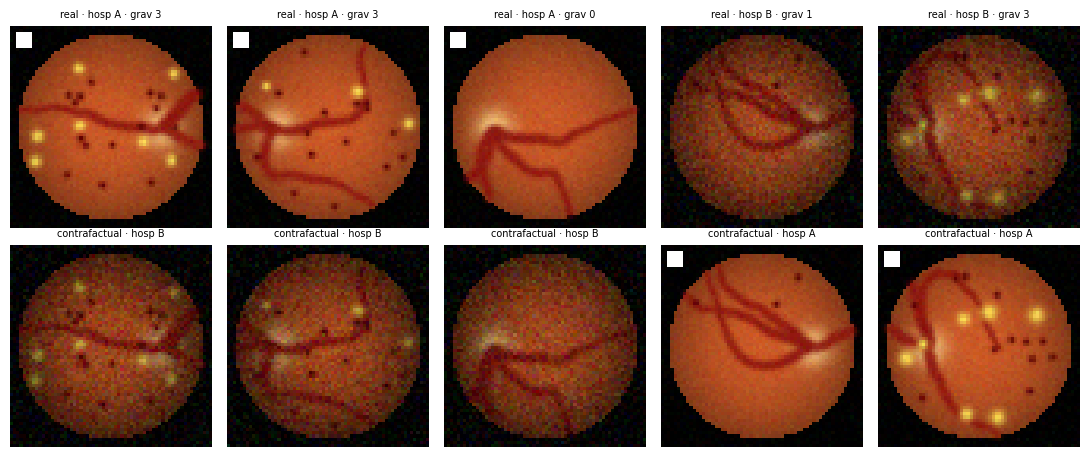

✅ Mismo ojo, mismas lesiones, distinto escáner


In [6]:
# ✅ Comprobación + el mismo ojo en los dos hospitales
fig, axs = plt.subplots(2, 5, figsize=(11, 4.6))
for j in range(5):
    p = tabla_iid.iloc[j].to_dict()
    p["gravedad"], p["n_ma"], p["n_ex"], p["semilla"] = int(p["gravedad"]), int(p["n_ma"]), int(p["n_ex"]), int(p["semilla"])
    cf = contrafactual_escaner(p)
    assert cf["hospital"] != p["hospital"], "El contrafactual debe estar en el otro hospital"
    assert cf["gravedad"] == p["gravedad"] and cf["n_ma"] == p["n_ma"], "La gravedad y las lesiones deben ser las mismas"
    axs[0, j].imshow(X_iid[j]); axs[0, j].set_title(f"real · hosp {p['hospital']} · grav {p['gravedad']}", fontsize=7)
    axs[1, j].imshow(renderizar(cf)); axs[1, j].set_title(f"contrafactual · hosp {cf['hospital']}", fontsize=7)
[a.axis("off") for a in axs.ravel()]; plt.tight_layout(); plt.show()
print("✅ Mismo ojo, mismas lesiones, distinto escáner")

---
## Parte 2 · La tasa de cambio contrafactual

Si un modelo mirara **solo la enfermedad**, cambiar el escáner no debería cambiar su predicción. Definimos:

$$\text{tasa de cambio} = \text{fracción de pacientes cuya predicción cambia al pasar a su contrafactual}$$

Un modelo ideal tendría 0 %; uno que solo mira el escáner se acercaría al 100 %.

### ✏️ Ejercicio 2.1 · Las imágenes contrafactuales del test iid

Crea `X_cf`: un array con la imagen contrafactual de **cada** paciente de `tabla_iid`, en el mismo orden.

Pista de `pandas`: `tabla.to_dict("records")` convierte la tabla en una lista de diccionarios, uno por fila, que es justo lo que espera `contrafactual_escaner`.

In [7]:
pacientes_iid = tabla_iid.to_dict("records")
X_cf = np.array([renderizar(contrafactual_escaner(p)) for p in pacientes_iid])

In [8]:
# ✅ Comprobación
assert X_cf.shape == X_iid.shape, f"X_cf debería tener forma {X_iid.shape}"
print("✅ Correcto")

✅ Correcto


### ✏️ Ejercicio 2.2 · `tasa_cambio(modelo, caracteristicas)`

Predice con el modelo sobre `X_iid` y sobre `X_cf` y devuelve la fracción de predicciones **distintas**. Es una línea.

<details><summary>▶ Pista</summary>

`(a != b)` sobre dos arrays da un array de `True`/`False`, y `.mean()` da la fracción de `True`.
</details>

In [10]:
def tasa_cambio(modelo, caracteristicas):
    return (modelo.predict(caracteristicas(X_iid)) != modelo.predict(caracteristicas(X_cf))).mean()

In [11]:
# ✅ Comprobación
tc_pix = tasa_cambio(modelo_pix, aplanar)
print(f"Modelo ingenuo: al cambiar SOLO el escáner, cambia el diagnóstico del {tc_pix:.0%} de los pacientes")
assert tc_pix > 0.3
print("✅ Correcto")

Modelo ingenuo: al cambiar SOLO el escáner, cambia el diagnóstico del 63% de los pacientes
✅ Correcto


### 🤔 Para pensar

La tasa de cambio mide el atajo **sin necesitar un test de otro mundo**: le basta con los pacientes del test iid. ¿Por qué es una métrica que **solo** puedes calcular con datos sintéticos?

---
## Parte 3 · Solución 1: repesar los datos

### La idea

El modelo usa el escáner porque, **en los datos de entrenamiento**, el hospital predice la enfermedad. ¿Y si damos más peso a los pacientes "raros" (sanos de A, enfermos de B) y menos a los "típicos", hasta que el hospital deje de predecir nada?

El peso de cada paciente es:

$$w = \frac{P(\text{hospital})\cdot P(\text{referable})}{P(\text{hospital},\ \text{referable})}$$

- Si una combinación es **más frecuente** de lo que sería con independencia, su peso es < 1.
- Si es **menos frecuente**, su peso es > 1.

En términos del DAG, es como **borrar la flecha `hospital → gravedad`** en los datos de entrenamiento.

### 🔍 Ejemplo: las tres probabilidades con `pandas`

In [12]:
p_h = tabla_tr["hospital"].value_counts(normalize=True)          # P(hospital)
p_y = tabla_tr["referable"].value_counts(normalize=True)         # P(referable)
p_hy = tabla_tr.groupby(["hospital", "referable"]).size() / len(tabla_tr)   # P(hospital, referable)

print("P(hospital):\n", p_h.round(3), "\n")
print("P(referable):\n", p_y.round(3), "\n")
print("P(hospital, referable):\n", p_hy.round(3), "\n")
print("Ejemplo → P(hospital=A, referable=0) =", round(p_hy[("A", 0)], 3))

P(hospital):
 hospital
B    0.503
A    0.497
Name: proportion, dtype: float64 

P(referable):
 referable
1    0.559
0    0.441
Name: proportion, dtype: float64 

P(hospital, referable):
 hospital  referable
A         0            0.089
          1            0.407
B         0            0.352
          1            0.151
dtype: float64 

Ejemplo → P(hospital=A, referable=0) = 0.089


### ✏️ Ejercicio 3.1 · Los pesos

Crea `w`: un array con el peso de **cada fila** de `tabla_tr`, aplicando la fórmula.

<details><summary>▶ Pista</summary>

```python
w = np.array([p_h[h] * p_y[y] / p_hy[(h, y)]
              for h, y in zip(tabla_tr["hospital"], tabla_tr["referable"])])
```
`zip` recorre las dos columnas a la vez.
</details>

In [13]:
w = np.array([p_h[h] * p_y[y] / p_hy[(h, y)]
              for h, y in zip(tabla_tr["hospital"], tabla_tr["referable"])])

In [14]:
# ✅ Comprobación
assert w.shape == (len(tabla_tr),)
for h in ["A", "B"]:
    m = (tabla_tr["hospital"] == h).values
    prev_w = np.average(tabla_tr["referable"][m], weights=w[m])
    print(f"Prevalencia PONDERADA de referable en {h}: {prev_w:.3f}")
m_A = (tabla_tr["hospital"] == "A").values
assert abs(np.average(tabla_tr["referable"][m_A], weights=w[m_A])
           - np.average(tabla_tr["referable"][~m_A], weights=w[~m_A])) < 0.01
print("✅ Con los pesos, la prevalencia es igual en los dos hospitales: el hospital ya no predice la etiqueta")

Prevalencia PONDERADA de referable en A: 0.559
Prevalencia PONDERADA de referable en B: 0.559
✅ Con los pesos, la prevalencia es igual en los dos hospitales: el hospital ya no predice la etiqueta


### ✏️ Ejercicio 3.2 · Entrenar con pesos

Crea `modelo_rw` igual que `modelo_pix`. Para pasarle los pesos dentro de un *pipeline*, se indica a qué paso van con el nombre del paso, dos guiones bajos y el parámetro:

```python
modelo.fit(X, y, logisticregression__sample_weight=w)
```

Después calcula `res_rw = evaluar(...)` y `tc_rw = tasa_cambio(...)`.

In [15]:
modelo_rw = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000))
modelo_rw.fit(aplanar(X_tr), y_tr, logisticregression__sample_weight=w)

res_rw = evaluar(modelo_rw, aplanar)
tc_rw = tasa_cambio(modelo_rw, aplanar)
print("Ingenuo :", {k: round(v, 3) for k, v in res_pix.items()}, f"| tasa de cambio {tc_pix:.0%}")
print("Repesado:", {k: round(v, 3) for k, v in res_rw.items()}, f"| tasa de cambio {tc_rw:.0%}")

Ingenuo : {'iid': np.float64(0.762), 'sin_confusion': np.float64(0.59), 'invertido': np.float64(0.447)} | tasa de cambio 63%
Repesado: {'iid': np.float64(0.756), 'sin_confusion': np.float64(0.629), 'invertido': np.float64(0.526)} | tasa de cambio 44%


In [16]:
# ✅ Comprobación
assert tc_rw < tc_pix, "El repesado debería reducir la tasa de cambio"
print("✅ Mejora algo... pero sigue lejos de ser un buen modelo")

✅ Mejora algo... pero sigue lejos de ser un buen modelo


### 🤔 Para pensar

El repesado quita el **incentivo** para usar el escáner, pero el modelo apenas mejora en el mundo invertido. ¿Por qué?

<details><summary>▶ Respuesta</summary>

Porque quitar el atajo no le enseña a ver las lesiones. Un modelo lineal sobre píxeles asigna un peso fijo a cada **posición** de la imagen, y las lesiones aparecen en **posiciones distintas** en cada paciente. No hay un píxel concreto que indique "aquí hay un microaneurisma". Sin el atajo, al modelo le queda muy poca señal útil.

**Lección:** el problema no era solo el sesgo de los datos, sino también **cómo representamos la imagen**.
</details>

---
## Parte 4 · Solución 2: una representación que vea las lesiones

### La idea

Las lesiones cambian **qué colores hay** en la imagen: más rojo oscuro (microaneurismas) y más amarillo (exudados). No importa **dónde** estén. Un **histograma de color** cuenta cuántos píxeles hay de cada color, sin fijarse en su posición, así que es justo lo que necesitamos.

### 🔍 Ejemplo: `np.histogramdd`

Dividimos cada canal (R, G, B) en `bins` intervalos. Con `bins=2` hay 2×2×2 = 8 "cajas" de color (rojo alto o bajo, verde alto o bajo, azul alto o bajo) y contamos cuántos píxeles caen en cada una.

In [17]:
img = X_iid[0]
pixeles = img.reshape(-1, 3)                 # (4096, 3): una fila por píxel con su R, G, B
conteo, _ = np.histogramdd(pixeles, bins=2, range=[(0, 1), (0, 1), (0, 1)])
print("forma del histograma:", conteo.shape, "→ aplanado:", conteo.ravel().shape)
print("cuántos píxeles en cada caja:", conteo.ravel().astype(int))
print("total:", int(conteo.sum()), "= 64 × 64")

forma del histograma: (2, 2, 2) → aplanado: (8,)
cuántos píxeles en cada caja: [1402    0    0    0 2565    0  104   25]
total: 4096 = 64 × 64


Con `bins=8` hay 8×8×8 = 512 cajas: suficiente detalle para distinguir el amarillo de un exudado del naranja del fondo.

Además aplicaremos `np.log1p` (el logaritmo de 1 + x). Hay cajas con miles de píxeles (el fondo) y otras con 3 o 4 (las lesiones), y el logaritmo comprime esas diferencias para que las cajas pequeñas también cuenten.

### ✏️ Ejercicio 4.1 · `hist_color(X, bins=8)`

Para cada imagen de `X`: calcula su histograma como en el ejemplo (con `bins=bins`), aplánalo con `.ravel()` y aplícale `np.log1p`. Devuelve un array de forma `(n, bins**3)`.

<details><summary>▶ Pista</summary>

Escribe primero una función auxiliar para una sola imagen y después usa `np.array([auxiliar(img) for img in X])`.
</details>

In [18]:
def hist_color(X, bins=8):
    def auxiliar(img):
        pixeles = img.reshape(-1, 3)
        conteo, _ = np.histogramdd(pixeles, bins=bins, range=[(0, 1), (0, 1), (0, 1)])
        return np.log1p(conteo).ravel()
    return np.array([auxiliar(img) for img in X])


In [19]:
# ✅ Comprobación
H = hist_color(X_tr[:3])
assert H.shape == (3, 512), f"La forma debería ser (3, 512); es {H.shape}"
assert np.allclose(np.expm1(H).sum(1), 4096), "Cada histograma debería sumar 4096 píxeles antes del log1p"
print("✅ Correcto: cada imagen pasa de 12 288 números a 512, y ninguno depende de la posición")

✅ Correcto: cada imagen pasa de 12 288 números a 512, y ninguno depende de la posición


### ✏️ Ejercicio 4.2 · Entrenar con histogramas

Crea `modelo_hist` igual que el ingenuo, pero con `C=0.1` y `max_iter=3000`. Entrénalo con `hist_color(X_tr)` **sin** pesos y calcula `res_hist` y `tc_hist`. Recuerda: a `evaluar` y `tasa_cambio` ahora les pasas `hist_color`.

🤔 Predice antes: ¿qué pasará en el mundo invertido?

In [21]:
modelo_hist = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
modelo_hist.fit(hist_color(X_tr), y_tr)
res_hist = evaluar(modelo_hist, hist_color)
tc_hist = tasa_cambio(modelo_hist, hist_color)
print("Histograma:", {k: round(v, 3) for k, v in res_hist.items()}, f"| tasa de cambio {tc_hist:.0%}")

Histograma: {'iid': np.float64(0.938), 'sin_confusion': np.float64(0.929), 'invertido': np.float64(0.942)} | tasa de cambio 9%


In [22]:
# ✅ Comprobación
assert res_hist["invertido"] > 0.85 and tc_hist < tc_rw
print("✅ Robusto en los tres mundos y mucho menos sensible al escáner")

✅ Robusto en los tres mundos y mucho menos sensible al escáner


### 🤔 Para pensar

La tasa de cambio del modelo de histogramas **no es 0**. ¿Qué rastro del escáner sigue apareciendo en un histograma de color? (Piensa en el brillo de B y en los 25 píxeles blancos de la marca de A.)

> 🧪 **Reto opcional:** entrena `modelo_hist` **con** los pesos `w`. ¿Baja más la tasa de cambio? Combinar las dos soluciones es una buena idea para el README.

---
## Parte 5 · Los resultados para tu README

### ✏️ Ejercicio 5.1 · La tabla final

Crea un `DataFrame` llamado `resultados` con una fila por modelo y estas columnas: `iid`, `sin_confusion`, `invertido` y `tasa_cambio`.

<details><summary>▶ Pista</summary>

Un `DataFrame` se puede crear a partir de un diccionario de diccionarios y después trasponer con `.T`:
```python
pd.DataFrame({
    "Píxeles": {**res_pix, "tasa_cambio": tc_pix},
    ...
}).T
```
`{**d, "clave": valor}` crea un diccionario nuevo con todo lo de `d` más una clave extra.
</details>

In [ ]:
resultados = pd.DataFrame({
    "Píxeles": {**res_pix, "tasa_cambio": tc_pix},
    "Repesado": {**res_rw, "tasa_cambio": tc
display(resultados.round(3))

In [ ]:
# ✅ Comprobación
assert list(resultados.columns) == ["iid", "sin_confusion", "invertido", "tasa_cambio"]
assert len(resultados) == 3
print("✅ Tabla lista")

### 🔍 La figura

Ejecuta la celda: guarda `resultados.png`, que puedes poner tal cual en tu README.

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1.3]})

mundos = ["iid", "sin_confusion", "invertido"]
nombres_mundo = ["iid\n(como entrenamiento)", "sin confusión", "invertido\n(B tiene más casos)"]
colores = ["#c44e52", "#dd8452", "#4c72b0"]
ancho = 0.26
for i, (modelo, fila) in enumerate(resultados.iterrows()):
    xs = np.arange(3) + (i - 1) * ancho
    axs[0].bar(xs, fila[mundos], width=ancho, label=modelo, color=colores[i])
axs[0].axhline(0.5, color="gray", ls="--", lw=1); axs[0].text(2.45, 0.51, "azar", color="gray", fontsize=8)
axs[0].set_xticks(range(3)); axs[0].set_xticklabels(nombres_mundo, fontsize=8)
axs[0].set_ylim(0, 1.15); axs[0].set_yticks([0, 0.25, 0.5, 0.75, 1]); axs[0].set_ylabel("balanced accuracy")
axs[0].legend(fontsize=8, loc="upper center", ncol=3, frameon=False)
axs[0].set_title("¿Funciona cuando cambia el hospital?", fontsize=10)

axs[1].barh(resultados.index[::-1], resultados["tasa_cambio"][::-1], color=colores[::-1])
axs[1].set_xlim(0, 1); axs[1].set_xlabel("fracción de diagnósticos que cambian")
axs[1].set_title("Cambiando SOLO el escáner", fontsize=10); axs[1].tick_params(axis="y", labelsize=8)
for a in axs:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("resultados.png", dpi=150, bbox_inches="tight"); plt.show()
print("✅ Guardado en resultados.png")

---
## Resumen del proyecto

| Notebook | Lo que construiste |
|---|---|
| 01 | Un **DAG** y un simulador de pacientes con intervenciones $do(\cdot)$ |
| 02 | Un **renderizador** de fondos de ojo con lesiones y escáner |
| 03 | Un **dataset** rápido, en disco, con varios mundos de test |
| 04 | Un **clasificador** con un 76 % en iid que en realidad mira el escáner |
| 05 | **Contrafactuales**, una métrica de atajo y dos soluciones comparadas |

### La historia para tu README (adáptala con tus números)

> Construí un simulador causal de retinografías en el que controlo la verdad. Un clasificador sobre píxeles obtiene un 76 % de balanced accuracy en test iid, pero cae por debajo del azar en un hospital con otra prevalencia y cambia el diagnóstico del 63 % de los pacientes si solo cambia el escáner. Repesar los datos reduce ese efecto pero no lo arregla; una representación invariante a la posición (histogramas de color) consigue un 94 % en todos los mundos y reduce la dependencia del escáner a un 9 %. Todo corre en CPU.

### Siguiente: de notebooks a proyecto

Convertir esto en un repositorio presentable: un paquete de Python con el generador, tests (tus celdas ✅ se convierten casi tal cual en tests), un README con la figura y una demo web con Gradio.